# **Lec12. 감성분류 : 금융 뉴스**
* https://wikidocs.net/24586

In [1]:
import os
# TensorFlow 안내 및 경고 로그 끄기 (3 = ERROR/FATAL 로그만 표시)
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
# oneDNN 최적화 관련 안내 문구 숨기기
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
# absl 라이브러리 초기화 전 경고(WARNING: All log messages...) 숨기기
os.environ['ABSL_LOGGING_MIN_LOG_LEVEL'] = '3'

import warnings
warnings.filterwarnings(action='ignore')

from sklearn import set_config
set_config(display="text")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
sns.set()

from tensorflow.keras.datasets import imdb
import re

from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.text import Tokenizer
from konlpy.tag import Okt
from nltk.corpus import stopwords
from tensorflow.keras.preprocessing.sequence import pad_sequences

from keras.models import Sequential
#from keras.layers import Conv2D, MaxPooling2D                          #---- CNN
from tensorflow.keras.layers import Embedding, SimpleRNN , LSTM, Input  #-----RNN
from keras.layers import Dense, Flatten                                 #---- FC

from sklearn.metrics import accuracy_score

#---------------------- 한글 폰트 지정 -----------------------
plt.rcParams["axes.unicode_minus"] = False                   # 마이너스 기호 깨짐 방지

#plt.rcParams["font.family"] = "Malgun Gothic"               #--------------윈도우 인 경우 
import matplotlib.font_manager as fm                         #--------------리눅스인 경우
font_path = "/usr/share/fonts/truetype/nanum/NanumGothic.ttf"
fm.fontManager.addfont(font_path)
font_prop = fm.FontProperties(fname=font_path)
plt.rcParams["font.family"] = font_prop.get_name()

# **뉴스 감성 분석**
* https://github.com/ukairia777/finance_sentiment_corpus

## 금융 뉴스 문장 감성 분석 데이터셋 (finance sentiment corpus)
* 기존 영어 데이터에 대해서 SOTA(State-of-the-Art)를 찍은 모델
* 언어 : 영어, 한국어
* 출처 : Finance Phrase Bank (Malo et al., 2014)
* 데이터 건수 : 4,846건
* 16명의 전문지식을 갖춘 연구자들에 의해 수동 라벨링하여 만들었음.
* 감정 라벨 : positive, neutral, negative

In [2]:
df = pd.read_csv("../datas/finance_data.csv")
df.head(3)

,labels,sentence,kor_sentence
0,neutral,"According to Gran, the company has no plans to...","Gran에 따르면, 그 회사는 회사가 성장하고 있는 곳이지만, 모든 생산을 러시아로..."
1,neutral,Technopolis plans to develop in stages an area...,테크노폴리스는 컴퓨터 기술과 통신 분야에서 일하는 회사들을 유치하기 위해 10만 평...
2,negative,The international electronic industry company ...,"국제 전자산업 회사인 엘코텍은 탈린 공장에서 수십 명의 직원을 해고했으며, 이전의 ..."


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4846 entries, 0 to 4845
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   labels        4846 non-null   str  
 1   sentence      4846 non-null   str  
 2   kor_sentence  4846 non-null   str  
dtypes: str(3)
memory usage: 1.3 MB


## **[1] EDA : 타켓 분포도**

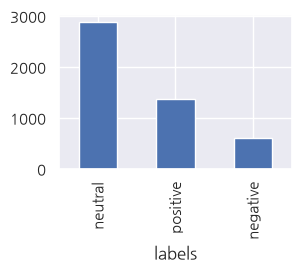

In [4]:
plt.figure(figsize=(3,2))
df['labels'].value_counts().plot(kind='bar')
plt.show()

## **전처리 & 가공**

### 결측 

In [5]:
df.isna().sum()

labels          0
sentence        0
kor_sentence    0
dtype: int64

### 중복

In [6]:
df[df.duplicated() == True] 

,labels,sentence,kor_sentence
1099,neutral,The issuer is solely responsible for the conte...,이 발표 내용에 대한 책임은 전적으로 발행자에게 있습니다.
1416,neutral,The report profiles 614 companies including ma...,"이 보고서는 블랙 앤 데커, 피스카스, 피스카스 브랜드, 후스크바르나 아웃도어 프로..."
2396,neutral,Ahlstrom's share is quoted on the NASDAQ OMX H...,알스트롬의 주가는 나스닥 OMX 헬싱키에서 인용되고 있다.
2567,neutral,SSH Communications Security Corporation is hea...,SSH 통신 보안 코퍼레이션은 핀란드 헬싱키에 본사를 두고 있다.
3094,neutral,Proha Plc ( Euronext :7327 ) announced today (...,Proha Plc (Euronext :7327)는 오늘 (5월 19일) 완전 소유 ...
3206,neutral,The company serves customers in various indust...,"공정 및 자원, 산업기계, 건축, 건축, 건설, 전기, 운송, 전자, 화학, 석유화..."


In [7]:
print(df.shape)
df = df.drop_duplicates()
print(df.shape)

(4846, 3)
(4840, 3)


### label 피쳐 인코딩

In [8]:
df['labels'].value_counts()

labels
neutral     2873
positive    1363
negative     604
Name: count, dtype: int64

In [9]:
df['labels'] = df['labels'].map({"neutral":0, "positive":1, "negative":2})
df.head(2)

,labels,sentence,kor_sentence
0,0,"According to Gran, the company has no plans to...","Gran에 따르면, 그 회사는 회사가 성장하고 있는 곳이지만, 모든 생산을 러시아로..."
1,0,Technopolis plans to develop in stages an area...,테크노폴리스는 컴퓨터 기술과 통신 분야에서 일하는 회사들을 유치하기 위해 10만 평...


In [10]:
df['labels'].value_counts()

labels
0    2873
1    1363
2     604
Name: count, dtype: int64

In [11]:
df['kor_sentence'][0]

'Gran에 따르면, 그 회사는 회사가 성장하고 있는 곳이지만, 모든 생산을 러시아로 옮길 계획이 없다고 한다.'

### 토큰화
* 불용어
* 정규화  : 2글자 미만 삭제
* Stemming
* konlpy 형태소 토큰화
* 인코딩

#### 영어

``` python

tk = Tokenizer()                                    #------불용어
tk.fit_on_texts(text_list)                          #------토큰화
encoded = tk.texts_to_sequences(df['sentence'])     #------인덱스사전 + 인코딩


#### 한국

``` python

for sent in df['kor_sentence']:
    불용어/정규화 처리
    
tk = Tokenizer()          
tk.fit_on_texts(text_list)                          #---토큰화
encoded = tk.texts_to_sequences(clean_text)  #---인덱스사전 + 인코딩

In [12]:
stop_words_list = stopwords.words('korea')

clean_sent_list = []
okt = Okt()
for sent in df['kor_sentence']:
    word_list = okt.morphs(sent, stem=True)
    p = re.compile(r'^[a-zA-Z0-9가-힣]{2,}$')
    res = [word for word in word_list if p.match(word)]
    clean_sent_list.append(res)
    
print(clean_sent_list[:2])

[['Gran', '따르다', '회사', '회사', '성장하다', '있다', '이지만', '모든', '생산', '러시아', '옮기다', '계획', '없다', '하다'], ['테크노', '폴리스', '컴퓨터', '기술', '통신', '분야', '에서', '하다', '회사', '유치하다', '위해', '10만', '평방미터', '이상', '면적', '단계', '으로', '개발', '하다', '계획', '이라고', '성명', '밝히다']]


In [13]:
tk = Tokenizer()
tk.fit_on_texts(clean_sent_list)
encoded = tk.texts_to_sequences(clean_sent_list)     #------- 인코딩(문장->숫자 바꾸기)
print(f"인코딩 : {encoded[:2]}")

인코딩 : [[4580, 28, 9, 9, 410, 2, 2498, 114, 40, 82, 1114, 87, 259, 1], [249, 650, 682, 60, 139, 172, 5, 1, 9, 1771, 84, 1772, 484, 109, 530, 411, 8, 45, 1, 87, 34, 1020, 18]]


* <font color=red><b>사전 크기

In [14]:
#print(f"사전 인덱스: {tk.word_index}")      #------- 인덱스 사전
vocab_size = len(tk.word_index) + 1
vocab_size

9154

### **[2] EDA : 데이터 분포도**

리뷰의 최대 길이 : 40
리뷰의 평균 길이 : 14.754338842975207


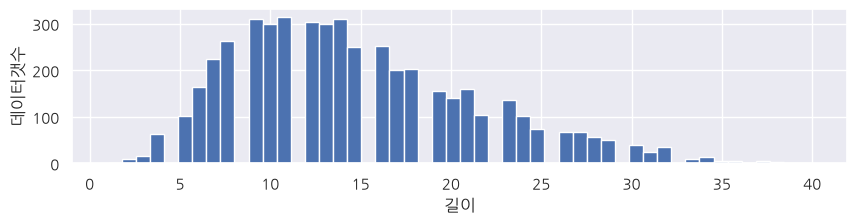

In [15]:
plt.figure(figsize=(10, 2))
print('리뷰의 최대 길이 :',max(len(review) for review in encoded))
print('리뷰의 평균 길이 :',sum(map(len, encoded))/len(encoded))

plt.hist([len(text) for text in encoded], bins=50)
plt.xlabel('길이')
plt.ylabel('데이터갯수')
plt.show()

### 패딩

In [16]:
df.shape

(4840, 3)

In [17]:
padded = pad_sequences(encoded)  #, maxlen=35)
padded[:1], padded.shape

(array([[   0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
            0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0,
            0,    0,    0,    0, 4580,   28,    9,    9,  410,    2, 2498,
          114,   40,   82, 1114,   87,  259,    1]], dtype=int32),
 (4840, 40))

In [18]:
df.head(2)

,labels,sentence,kor_sentence
0,0,"According to Gran, the company has no plans to...","Gran에 따르면, 그 회사는 회사가 성장하고 있는 곳이지만, 모든 생산을 러시아로..."
1,0,Technopolis plans to develop in stages an area...,테크노폴리스는 컴퓨터 기술과 통신 분야에서 일하는 회사들을 유치하기 위해 10만 평...


## 학습 , 테스트 데이터 분리(8:2)

In [19]:
X = padded
y = df['labels']

X8,X2, y8,y2 = train_test_split(X, y, test_size=0.2
                                 , shuffle=True, random_state=1234
                                 , stratify=y)
X8.shape, X2.shape, y8.shape, y2.shape

((3872, 40), (968, 40), (3872,), (968,))

## LSTM 모델 생성/학습

```python
Embedding(
    input_dim,   #-------사전크기(단어수)
    output_dim,  #-------임베딩 벡터(차원축소) 크기
    ... )

In [20]:
# 문장 하나당 단어/토큰의 최대 개수를 max_len 변수라고 가정합니다.
max_len = 40 

model = Sequential([
    #Embedding(input_dim=vocab_size, output_dim=100) ,
    Embedding(input_dim=vocab_size, output_dim=60, input_shape=(max_len, ) ),
    LSTM(64, activation='tanh') ,
    Dense(3, activation='softmax')  #----3종분류
])
model.compile(loss='sparse_categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 40, 60)         │       549,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        32,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 581,435 (2.22 MB)

 Trainable params: 581,435 (2.22 MB)

 Non-trainable params: 0 (0.00 B)

In [21]:
fit_res = model.fit(X8, y8, epochs=30, batch_size=32
                    , validation_split=0.2
                    #, validation_data=(X2, y2)
                   )

Epoch 1/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 3s 16ms/step - accuracy: 0.6112 - loss: 0.8858 - val_accuracy: 0.7071 - val_loss: 0.7156
Epoch 2/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.7656 - loss: 0.5720 - val_accuracy: 0.7690 - val_loss: 0.5783
Epoch 3/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.8983 - loss: 0.2937 - val_accuracy: 0.7794 - val_loss: 0.5876
Epoch 4/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9519 - loss: 0.1384 - val_accuracy: 0.7484 - val_loss: 0.7662
Epoch 5/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.9777 - loss: 0.0849 - val_accuracy: 0.7226 - val_loss: 0.9688
Epoch 6/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9851 - loss: 0.0521 - val_accuracy: 0.7768 - val_loss: 0.8995
Epoch 7/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9871 - loss: 0.0430 - val_accuracy: 0.7690 - val_loss: 0.9922
Epoch 8/30
97/97 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step - accuracy: 0.9916 - loss: 0.0314 - val_accuracy: 0.6916 - v

### 평가 시각화

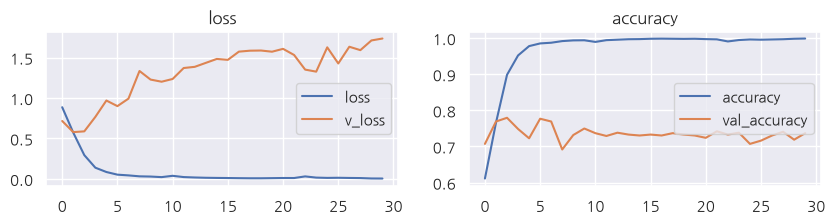

In [22]:
plt.figure(figsize=(10,2))
ax1 = plt.subplot(1,2,1)
ax1.plot(fit_res.history['loss']   ,   label="loss")
ax1.plot(fit_res.history['val_loss'],  label="v_loss")
ax1.legend()
ax1.set_title("loss")

ax2 = plt.subplot(1,2,2)
ax2.plot(fit_res.history['accuracy']   ,   label="accuracy")
ax2.plot(fit_res.history['val_accuracy'],  label="val_accuracy")
ax2.legend()
ax2.set_title("accuracy")

plt.show()

## test 데이터 예측

In [23]:
np.argmax([9.9989349, 2.7082568, 7.9327430])

np.int64(0)

In [24]:
proba = model.predict(X2)
print(proba[:2], proba.shape)

pred = np.argmax(proba, axis=1)
print(pred.shape, y2.shape)
print(pred[:5])

acc = accuracy_score(y2, pred)
print(acc)

31/31 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step
[[9.9995297e-01 3.3210192e-05 1.3760220e-05]
 [9.9998218e-01 1.2774868e-05 5.0182202e-06]] (968, 3)
(968,) (968,)
[0 0 0 1 0]
0.7076446280991735


In [26]:
from sklearn.metrics import confusion_matrix
cm = confusion_matrix(y2, pred)
print(cm)

[[459  93  23]
 [100 160  12]
 [ 39  16  66]]


# **IMDB 영화 리뷰 감성분석**

## **Toy Dataset Load**

In [ ]:
(X_train, y_train), (X_test, y_test) = imdb.load_data()

print('훈련용 리뷰 개수 : {}'.format(len(X_train)))
print('테스트용 리뷰 개수 : {}'.format(len(X_test)))
num_classes = len(set(y_train))
print('카테고리 : {}'.format(num_classes))

In [ ]:
print('첫번째 훈련용 리뷰 :',X_train[0])
print('첫번째 훈련용 리뷰의 레이블 :',y_train[0])

## **EDA**

In [ ]:
plt.figure(figsize=(10, 2))
print('리뷰의 최대 길이 :',max(len(review) for review in X_train))
print('리뷰의 평균 길이 :',sum(map(len, X_train))/len(X_train))
plt.hist([len(review) for review in X_train], bins=50)
plt.xlabel('길이')
plt.ylabel('데이터갯수')
plt.show()

In [ ]:
plt.figure(figsize=(10, 2))
reviews_length = [len(review) for review in X_train]

print('리뷰의 최대 길이 : {}'.format(np.max(reviews_length)))
print('리뷰의 평균 길이 : {}'.format(np.mean(reviews_length)))

plt.subplot(1,2,1)
plt.boxplot(reviews_length)
plt.subplot(1,2,2)
plt.hist(reviews_length, bins=50)
plt.show()